In [1]:
import joblib
import pandas as pd
import shap
import matplotlib.pyplot as plt
import numpy as np

c:\Users\rkalbag\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df_train = pd.read_csv("../data/ml_ready/train.csv")
X_train = df_train.drop("next_monthly_revenue", axis=1)

df_valid = pd.read_csv("../data/ml_ready/valid.csv")
X_valid = df_valid.drop("next_monthly_revenue", axis=1)

In [3]:
loaded_scaler = joblib.load("../models/scaler.joblib")
loaded_models = joblib.load("../models/random_forest_model.joblib")

In [4]:
X_train_scaled = loaded_scaler.transform(X_train)
X_valid_scaled = loaded_scaler.transform(X_valid)

In [5]:
X_train.shape, X_valid.shape

((43534, 38), (21762, 38))

In [6]:
rf_y_pred = loaded_models.predict(X_valid_scaled)

In [7]:
type(loaded_models)

sklearn.ensemble._forest.RandomForestRegressor

In [8]:
background_sample = shap.sample(X_train_scaled, 100)
explainer = shap.TreeExplainer(loaded_models, data=background_sample)

In [9]:
shap_values = explainer(X_valid_scaled[:1000], check_additivity=False)

 99%|===================| 988/1000 [00:37<00:00]        

In [10]:
X_valid_scaled[:1000]

array([[-1.59320281e+00, -3.96986209e-01, -4.32364190e-01, ...,
        -4.98411882e-01, -1.84500827e-01, -3.98175517e-01],
       [-1.30352715e+00, -4.12223914e-01, -4.33940176e-01, ...,
        -5.06127284e-01, -1.84500827e-01, -4.14448345e-01],
       [-1.01385149e+00, -4.01931035e-01, -4.29247519e-01, ...,
        -5.15200427e-01, -1.71524042e-01, -4.05269382e-01],
       ...,
       [-1.01385149e+00,  3.79584260e-02, -1.37152537e-01, ...,
         1.11434572e-01, -1.84500827e-01,  6.63156324e-02],
       [-7.24175835e-01, -2.53022638e-02, -1.50302405e-01, ...,
        -4.45197904e-02, -1.84500827e-01, -1.24246159e-03],
       [-4.34500178e-01, -1.62875707e-01, -1.28158510e-02, ...,
        -1.01778397e-01, -1.84500827e-01, -1.48161498e-01]],
      shape=(1000, 38))

In [11]:
shap_values

.values =
array([[-1.46321720e+02,  2.39478982e+02, -3.25394175e+03, ...,
        -4.17925254e+02, -3.80153424e+01,  2.99802223e+02],
       [-2.81132653e+01,  2.92509511e+02, -3.28758588e+03, ...,
        -4.35130682e+02, -3.33680357e+01,  3.06472283e+02],
       [-2.70252671e+01,  2.63350394e+02, -3.24416805e+03, ...,
        -4.50408937e+02, -3.75907284e+01,  3.02822880e+02],
       ...,
       [-8.57782586e+00,  1.24647260e+02, -2.46168794e+03, ...,
         2.78635487e+01, -3.37207617e+01,  1.51708400e+02],
       [ 7.51969758e-01,  1.47816490e+02, -2.46701988e+03, ...,
        -1.49299162e+02, -3.17571553e+01,  9.37725537e+01],
       [ 1.44856887e+00,  1.50847651e+02, -1.89359300e+03, ...,
        -2.02310520e+02, -3.71466431e+01,  1.08544243e+02]],
      shape=(1000, 38))

.base_values =
array([62502.92656456, 62502.92656456, 62502.92656456, 62502.92656456,
       62502.92656456, 62502.92656456, 62502.92656456, 62502.92656456,
       62502.92656456, 62502.92656456, 62502.926564

In [12]:
shap_values.feature_names = X_valid.columns

In [31]:
shap.plots.bar(shap_values, show=False)
plt.savefig("../docs/images/shap_global_importance.png", dpi=300, bbox_inches="tight")
plt.close()

In [32]:
shap.plots.beeswarm(shap_values, show=False)
plt.savefig("../docs/images/shap_beeswarm_plot.png", dpi=300, bbox_inches="tight")
plt.close()

In [15]:
y_valid = df_valid["next_monthly_revenue"]
y_valid.shape

(21762,)

In [16]:
actual = y_valid[:1000]
predicted = rf_y_pred[:1000]

In [17]:
absolute_error = abs(actual-predicted)

In [18]:
low_prediction_error = absolute_error[:1000].argmin()
high_prediction_error = absolute_error[:1000].argmax()
typical_prediction = np.abs(rf_y_pred[:1000] - np.median(rf_y_pred[:1000])).argmin()

In [19]:
low_prediction_error, high_prediction_error, typical_prediction

(np.int64(71), np.int64(176), np.int64(136))

In [20]:
print("Actual y_valid", y_valid[71], y_valid[176], y_valid[136])
print("Predicted rf_y_pred", rf_y_pred[71], rf_y_pred[176], rf_y_pred[136])
print("Absolute Error", absolute_error[:1000].min(), absolute_error[:1000].max(), abs(y_valid[136] - rf_y_pred[136]))

Actual y_valid 1454.64 73361.37 2022.84
Predicted rf_y_pred 1454.4899818077336 34273.293949423416 3766.634761893991
Absolute Error 0.15001819226654334 39088.07605057658 1743.7947618939909


In [21]:
row_values_low =shap_values[71].values
feature_names_low = shap_values[71].feature_names

row_values_high =shap_values[176].values
feature_names_high = shap_values[176].feature_names

row_values_median =shap_values[136].values
feature_names_median = shap_values[136].feature_names


shap_series_low = pd.Series(row_values_low, index=feature_names_low)
shap_series_high = pd.Series(row_values_high, index=feature_names_high)
shap_series_median = pd.Series(row_values_median, index=feature_names_median)

In [22]:
top_5_positive_low = shap_series_low[shap_series_low > 0].nlargest(5)
top_5_positive_high = shap_series_high[shap_series_high > 0].nlargest(5)
top_5_positive_median = shap_series_median[shap_series_median > 0].nlargest(5)

top_5_negative_low = shap_series_low[shap_series_low < 0].nsmallest(5)
top_5_negative_high = shap_series_high[shap_series_high < 0].nsmallest(5)
top_5_negative_median = shap_series_median[shap_series_median < 0].nsmallest(5)

##### Top 5 Positive Contributors for Low, High & Typical Prediction Error

In [23]:
print("--- Top 5 Positive Contributors for [71] ---")
print(top_5_positive_low)

print("--- Top 5 Positive Contributors for [136] ---")
print(top_5_positive_median)

print("--- Top 5 Positive Contributors for [176] ---")
print(top_5_positive_high)

--- Top 5 Positive Contributors for [71] ---
average_profit           766.536090
total_profit             714.051635
discounted_revenue       312.331405
monthly_revenue          260.987615
total_discount_amount    240.881255
dtype: float64
--- Top 5 Positive Contributors for [136] ---
average_profit        681.990339
total_profit          658.795777
discounted_revenue    270.856063
monthly_revenue       234.660313
lag_3_revenue         209.172283
dtype: float64
--- Top 5 Positive Contributors for [176] ---
average_profit          496.890212
total_profit            266.933246
monthly_revenue         167.905261
moving_stdev_3_month    112.200274
discounted_revenue       95.938719
dtype: float64


##### Top 5 Negative Contributors for Low, High & Typical Prediction Error

In [24]:
print("--- Top 5 Negative Contributors for [71] ---")
print(top_5_negative_low)

print("--- Top 5 Negative Contributors for [136] ---")
print(top_5_negative_median)

print("--- Top 5 Negative Contributors for [176] ---")
print(top_5_negative_high)

--- Top 5 Negative Contributors for [71] ---
moving_avg_12_month     -35585.744710
moving_avg_6_month       -8876.335110
maximum_selling_price    -8243.129604
revenue_per_customer     -3307.503798
minimum_selling_price    -2624.698385
dtype: float64
--- Top 5 Negative Contributors for [136] ---
moving_avg_12_month     -34271.618239
moving_avg_6_month       -8101.323628
maximum_selling_price    -7946.772443
revenue_per_customer     -3201.779307
minimum_selling_price    -2633.535259
dtype: float64
--- Top 5 Negative Contributors for [176] ---
moving_avg_12_month     -15065.495067
moving_avg_6_month       -2734.725151
revenue_per_customer     -2517.950275
maximum_selling_price    -2486.323308
minimum_selling_price    -2100.561300
dtype: float64


##### Waterfall Plots for Low, High & Typical Prediction Error

In [33]:
shap.plots.waterfall(shap_values[71], max_display=10, show=False)
plt.savefig("../docs/images/shap_waterfall_for_71.png",dpi=300, bbox_inches="tight")
plt.close()

In [40]:
shap.plots.waterfall(shap_values[136], max_display=10, show=False)
plt.savefig("../docs/images/shap_waterfall_for_136.png", dpi=300, bbox_inches="tight")
plt.close()

In [35]:
shap.plots.waterfall(shap_values[176], max_display=10, show=False)
plt.savefig("../docs/images/shap_waterfall_for_176.png", dpi=300, bbox_inches="tight")
plt.close()

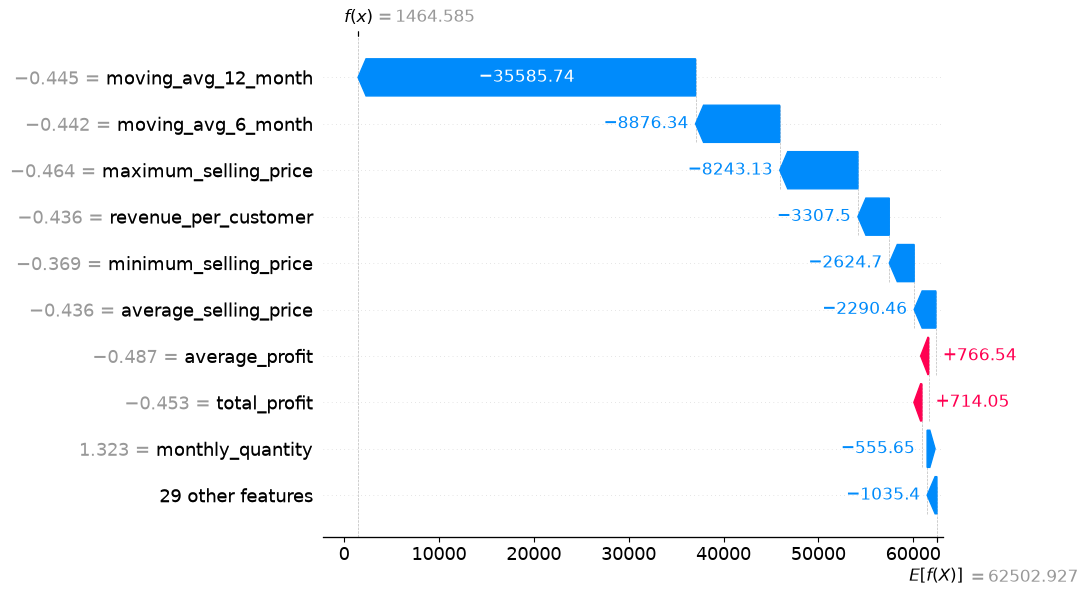

In [47]:
shap.plots.waterfall(shap_values[71], show=True)